# Task 1: Supervised models (regression and classification)

Compares a baseline and a Random Forest for each task on a shared feature set:
time features, cyclical hour / day-of-week / month, whole-day holiday flag and weather encodings.

**Data source: no real accident dataset was sourced.** Classification uses the documented proxy label `high_risk`
(High/Severe congestion with Thunderstorm, Snow, Squall, Fog, Mist, Haze or Smoke weather), so it is **not** an accident prediction.
Because `weather_main` is both a label input and a feature, classification scores are inflated (circular).

The modelling code lives in `../train_models.py`; this notebook reuses it so results match the script and MLflow runs.
Results are associations from one time-based split, without tuning.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

PART_DIR = Path.cwd().resolve().parent
sys.path.insert(0, str(PART_DIR))
import train_models as tm

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s", force=True)
LOG = logging.getLogger("task1_notebook")
pd.options.display.float_format = "{:,.4f}".format
plt.rcParams["figure.dpi"] = 100

## 1. Load data and build the shared features

- Reads the labelled CSV from `prepare_labels.py` (hourly traffic, weather, holiday flag and the proxy `high_risk` label).
- `build_features` sorts rows by time and creates the 28 features used by **both** tasks: hour, day of week, month, weekend flag, sine/cosine versions of hour, day of week and month (so hour 23 sits next to hour 0), a holiday flag covering the whole date, temperature in °C, rain, snow, cloud cover and one-hot `weather_main`.
- The table below is a quick sanity check of each feature's mean, spread and range.

In [2]:
raw = pd.read_csv(PART_DIR / "data" / "processed" / "Metro_Interstate_Traffic_Volume_ml.csv", encoding="utf-8-sig")
df, feats = tm.build_features(raw)
LOG.info("%d rows, %d features.", *feats.shape)
feats.describe().T[["mean", "std", "min", "max"]]

2026-11-15 16:16:32,942 INFO train_models: Holiday flag: 53 holiday dates spread over 1203 hours.


2026-11-15 16:16:32,949 INFO task1_notebook: 40575 rows, 28 features.


,mean,std,min,max
hour,11.5148,6.9499,0.0000,23.0000
day_of_week,3.0068,1.9989,0.0000,6.0000
month,6.4890,3.3736,1.0000,12.0000
is_weekend,0.2858,0.4518,0.0000,1.0000
hour_sin,-0.0017,0.7060,-1.0000,1.0000
hour_cos,0.0053,0.7082,-1.0000,1.0000
dow_sin,-0.0025,0.7065,-0.9749,0.9749
dow_cos,-0.0029,0.7078,-0.9010,1.0000
month_sin,-0.0085,0.7018,-1.0000,1.0000
month_cos,-0.0437,0.7110,-1.0000,1.0000


## 2. Exploration: what drives the targets?

- **Left:** average traffic by hour. It is bimodal (a morning and an afternoon peak, very low overnight), which is why a straight line in `hour` fits poorly.
- **Right:** share of hours labelled `high_risk` for each weather type. Hours per weather type are in the table, so rare types (Smoke, Squall, Fog) rest on few hours.

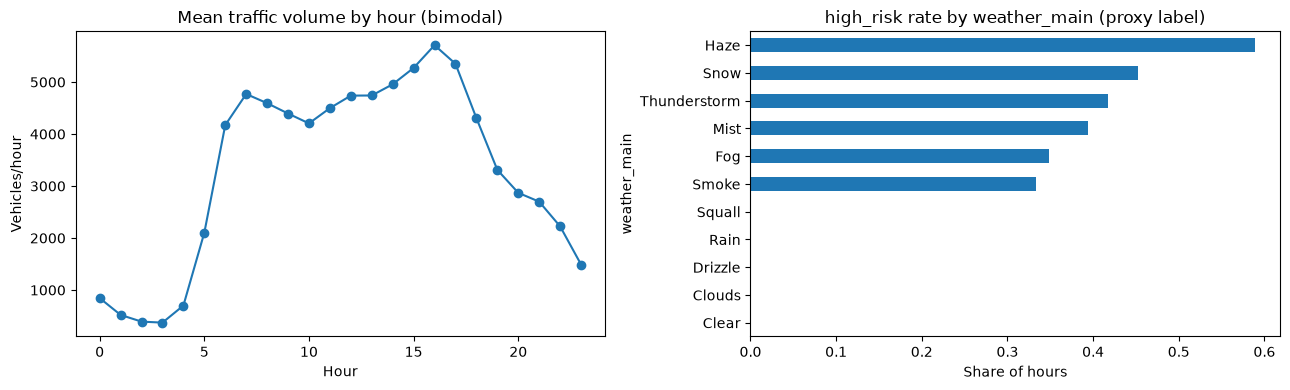

,high_risk_rate,hours
weather_main,,
Clear,0.0000,13366
Clouds,0.0000,15123
Drizzle,0.0000,515
Rain,0.0000,4769
Squall,0.0000,1
Smoke,0.3333,15
Fog,0.3483,201
Mist,0.3946,3069
Thunderstorm,0.4172,453


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(feats["hour"])[tm.REG_TARGET].mean().plot(ax=axes[0], marker="o")
axes[0].set(title="Mean traffic volume by hour (bimodal)", xlabel="Hour", ylabel="Vehicles/hour")

by_weather = df.groupby("weather_main")[tm.CLF_TARGET].agg(["mean", "size"]).sort_values("mean")
by_weather["mean"].plot.barh(ax=axes[1])
axes[1].set(title="high_risk rate by weather_main (proxy label)", xlabel="Share of hours")
plt.tight_layout()
plt.show()
by_weather.rename(columns={"mean": "high_risk_rate", "size": "hours"})

The `high_risk` rate is exactly zero for Clear, Clouds, Drizzle and Rain by construction, so weather is a direct input to the label.

## 3. Time-based split and model training

- The first 80% of hours (oldest) train the models and the last 20% (newest) test them. A random split would leak neighbouring hours into the test set and ignores the gaps in the data.
- Regression predicts `traffic_volume`: two reference baselines (train mean, mean by hour) plus Linear Regression and Random Forest.
- Classification predicts the proxy `high_risk` label: Logistic Regression and Random Forest, both with class weights because only about 7-9% of hours are positive.
- Training uses the same code as `train_models.py`, so the numbers match the script and the MLflow runs.

In [4]:
cut = tm.time_split(df)
X_train, X_test = feats.iloc[:cut], feats.iloc[cut:]
yr_train, yr_test = df[tm.REG_TARGET].iloc[:cut], df[tm.REG_TARGET].iloc[cut:]
yc_train, yc_test = df[tm.CLF_TARGET].iloc[:cut], df[tm.CLF_TARGET].iloc[cut:]
reg_rows, reg_models = tm.run_regression(X_train, X_test, yr_train, yr_test)
clf_rows, clf_models = tm.run_classification(X_train, X_test, yc_train, yc_test)

2026-11-15 16:16:33,216 INFO train_models: Time split: train 32460 rows (2012-10-02 09:00:00 to 2017-10-26 17:00:00), test 8115 rows (2017-10-26 18:00:00 to 2018-09-30 23:00:00).


2026-11-15 16:16:33,277 INFO train_models: Regression Linear Regression: MAE=801.474, R2=0.735.


2026-11-15 16:16:35,681 INFO train_models: Regression Random Forest: MAE=238.871, R2=0.959.


2026-11-15 16:16:35,776 INFO train_models: Classification Logistic Regression: Accuracy=0.957, Precision=0.689, Recall=0.993, F1=0.814, ROC_AUC=0.994, PR_AUC=0.922.


2026-11-15 16:16:36,991 INFO train_models: Classification Random Forest: Accuracy=0.986, Precision=0.880, Recall=0.986, F1=0.930, ROC_AUC=0.997, PR_AUC=0.955.


## 4. Metrics

All scores are on the test period only.

- **Regression:** MAE is the average error in vehicles/hour (lower is better); R² is the share of variance explained (higher is better, 0 means no better than predicting the mean).
- **Classification:** precision = share of predicted high-risk hours that are truly positive; recall = share of true positives found; F1 balances the two; ROC AUC and PR AUC measure ranking quality across thresholds (PR AUC is more telling with rare positives). Accuracy alone is misleading with so few positives.
- A model should beat the baselines to be worth using. Classification scores are inflated because weather is also an input to the label.

In [5]:
reg_table = pd.DataFrame(reg_rows).set_index("model").drop(columns="task")
clf_table = pd.DataFrame(clf_rows).set_index("model").drop(columns="task")
display(reg_table)
display(clf_table)

,MAE,R2
model,,
Baseline: train mean,"1,723.9769",-0.0001
Baseline: mean by hour,622.0420,0.7834
Linear Regression,801.4739,0.7348
Random Forest,238.8709,0.9588


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
model,,,,,,
Logistic Regression,0.9574,0.6894,0.9934,0.8140,0.9945,0.9225
Random Forest,0.9861,0.8804,0.9856,0.9300,0.9966,0.9545


## 5. Regression diagnostics

- **Left and middle:** actual vs predicted traffic. Points on the red line are perfect predictions; a wide cloud means large errors.
- **Right:** average absolute error for each hour of the day, showing when each model struggles.

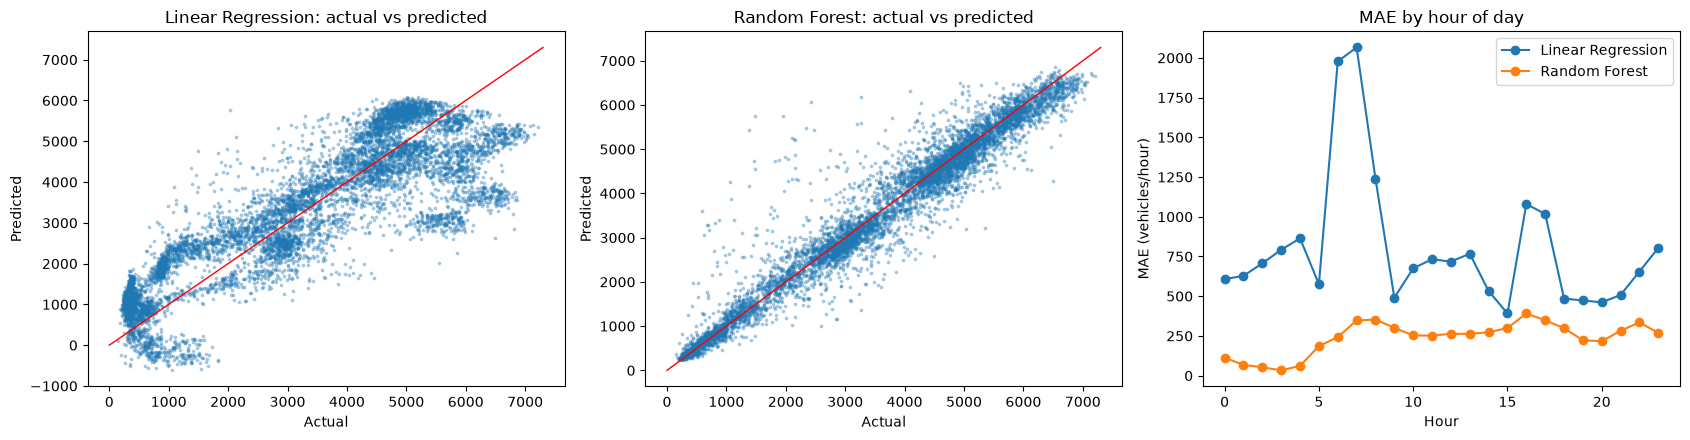

In [6]:
lin = reg_models[("regression", "Linear Regression")]
rf = reg_models[("regression", "Random Forest")]
pred = {"Linear Regression": lin.predict(X_test), "Random Forest": rf.predict(X_test)}

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, p) in zip(axes[:2], pred.items()):
    ax.scatter(yr_test, p, s=3, alpha=0.3)
    ax.plot([0, 7300], [0, 7300], color="red", lw=1)
    ax.set(title=f"{name}: actual vs predicted", xlabel="Actual", ylabel="Predicted")
abs_err = pd.DataFrame({n: np.abs(yr_test.values - p) for n, p in pred.items()})
abs_err.groupby(X_test["hour"].values).mean().plot(ax=axes[2], marker="o")
axes[2].set(title="MAE by hour of day", xlabel="Hour", ylabel="MAE (vehicles/hour)")
plt.tight_layout()
plt.show()

## 6. Classification diagnostics

- **ROC and precision-recall curves:** show performance at every probability threshold; curves closer to the top-left (ROC) or top-right (PR) are better.
- **Confusion matrices:** counts of correct and wrong predictions at the fixed 0.5 threshold. Rows are the true class (0 = not high risk, 1 = high risk) and columns the predicted class; off-diagonal cells are errors.

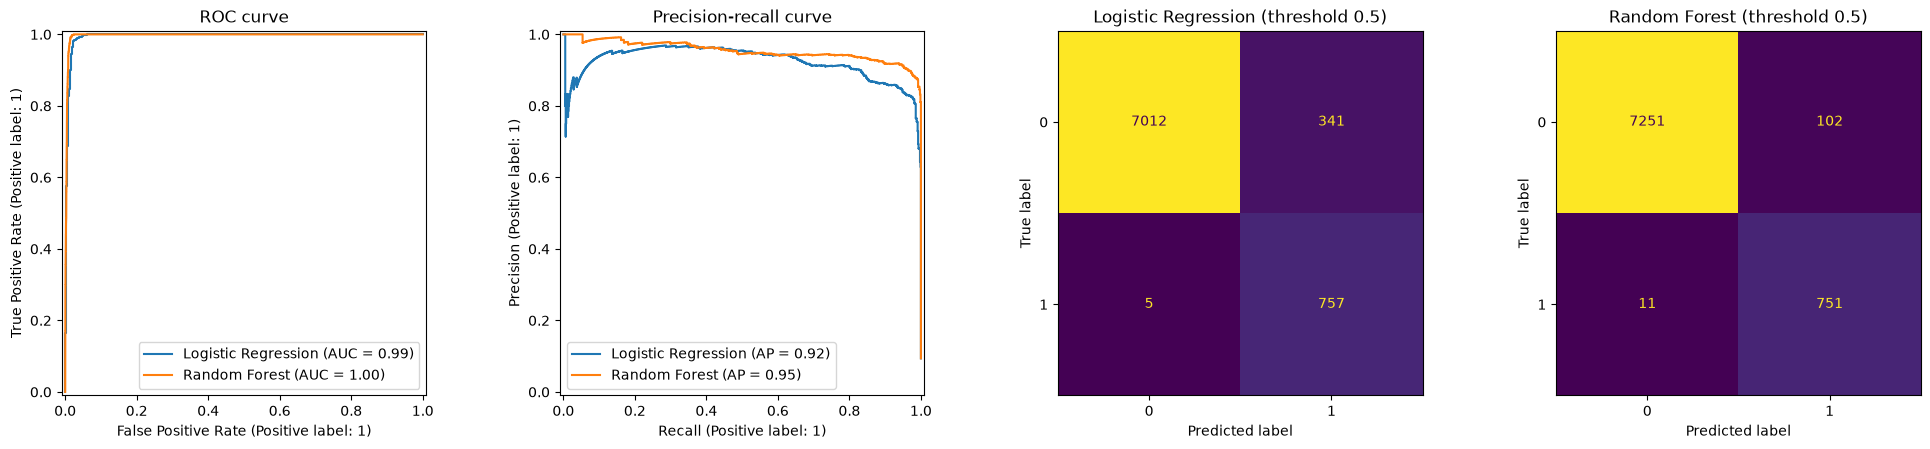

In [7]:
proba = {n[1]: m.predict_proba(X_test)[:, 1] for n, m in clf_models.items()}
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for name, p in proba.items():
    RocCurveDisplay.from_predictions(yc_test, p, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(yc_test, p, name=name, ax=axes[1])
axes[0].set_title("ROC curve")
axes[1].set_title("Precision-recall curve")
for ax, (name, p) in zip(axes[2:], proba.items()):
    ConfusionMatrixDisplay.from_predictions(
        yc_test, (p >= tm.DECISION_THRESHOLD).astype(int), ax=ax, colorbar=False
    )
    ax.set_title(f"{name} (threshold {tm.DECISION_THRESHOLD})")
plt.tight_layout()
plt.show()

## 7. Random Forest feature importance

Shows which features the Random Forests relied on most (importances sum to 1 per task). Regression leans on the hour features; classification leans on weather and hour, which reflects how the proxy label is defined. Importance describes the model's behaviour, not causes.

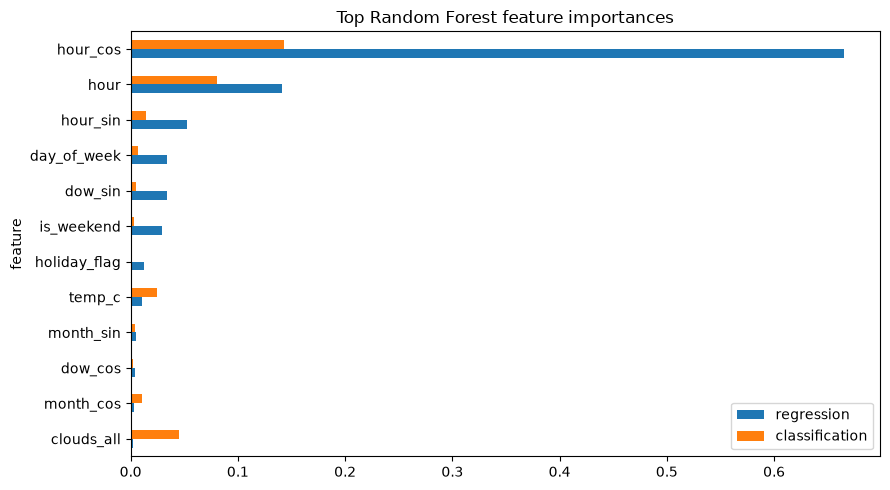

,regression,classification
feature,,
weather_main_Clouds,0.0006,0.2038
hour_cos,0.6655,0.1429
weather_main_Clear,0.0003,0.1289
weather_main_Mist,0.0002,0.0968
hour,0.1407,0.0809
weather_main_Snow,0.0004,0.0675
weather_main_Rain,0.0002,0.0559
weather_main_Haze,0.0001,0.0509


In [8]:
importance = tm.importance_table(reg_models | clf_models, feats.columns).set_index("feature")
importance.columns = ["regression", "classification"]
top = importance.head(12)  # already sorted by regression importance
top.iloc[::-1].plot.barh(figsize=(9, 5), title="Top Random Forest feature importances")
plt.tight_layout()
plt.show()
importance.sort_values("classification", ascending=False).head(8)

## 8. Logged MLflow runs

Created by `python Part-3/train_models.py`; view them with `mlflow ui --backend-store-uri sqlite:///Part-3/mlflow.db`.

This reads the saved MLflow runs back and lists their metrics per task. They should match section 4. Each task only logs its own metrics, so the two tables have different columns.

In [9]:
import mlflow

mlflow.set_tracking_uri(f"sqlite:///{(PART_DIR / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["task1-supervised-models"])
for task in ("regression", "classification"):
    task_runs = runs[runs["tags.task"] == task].set_index("tags.mlflow.runName")
    metric_cols = [c for c in task_runs.columns if c.startswith("metrics.")]
    display(task_runs[metric_cols].dropna(axis=1, how="all").rename(columns=lambda c: c.removeprefix("metrics.")))

,MAE,R2
tags.mlflow.runName,,
regression - Random Forest,238.8709,0.9588
regression - Linear Regression,801.4739,0.7348
regression - Baseline: mean by hour,622.0420,0.7834
regression - Baseline: train mean,"1,723.9769",-0.0001


,Recall,F1,ROC_AUC,Accuracy,PR_AUC,Precision
tags.mlflow.runName,,,,,,
classification - Random Forest,0.9856,0.9300,0.9966,0.9861,0.9545,0.8804
classification - Logistic Regression,0.9934,0.8140,0.9945,0.9574,0.9225,0.6894


## 9. Observations

- Random Forest beats the linear/logistic baselines on both tasks.
- Linear Regression does not beat the simple mean-by-hour baseline: traffic is strongly non-linear in hour.
- Hour features dominate Random Forest importance for regression; weather and temperature add little, consistent with the project hypothesis.
- Classification scores are inflated by the circular weather features and describe how well the proxy rule is reconstructed, not real accident risk.
- The test period (to Sep 2018) has a higher positive rate (9.4%) than training (6.8%), and 2018 coverage is partial.
- No tuning, cross-validation or fairness/subgroup analysis yet; these findings are associations only.